In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, cohen_kappa_score,
    matthews_corrcoef, confusion_matrix, roc_curve, precision_recall_curve
)
import optuna
import shap

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("XGBoost, Optuna, and SHAP libraries loaded.")

XGBoost, Optuna, and SHAP libraries loaded.


In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("28-10-2026", "Task 3", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

cat_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = num_features + cat_cols

df_X_train = pd.DataFrame(X_train_trans, columns=all_feature_names)
df_X_test = pd.DataFrame(X_test_trans, columns=all_feature_names)

Loaded dataset: 23486 rows, 23 columns


In [3]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=25),
        'max_depth': trial.suggest_int('max_depth', 3, 7),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.20, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0, step=0.1),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0, step=0.1),
        'gamma': trial.suggest_float('gamma', 0.0, 3.0, step=0.5),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 6),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 5.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
        'eval_metric': 'logloss',
        'random_state': 42,
        'n_jobs': -1
    }
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = cross_val_score(
        XGBClassifier(**params),
        X_train_trans, y_train,
        cv=cv, scoring='f1_macro', n_jobs=-1
    )
    return scores.mean()

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler)
study.optimize(objective, n_trials=30)

print(f"Optimal Stratified CV Macro F1: {study.best_value:.4f}")
print("Best Hyperparameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Optimal Stratified CV Macro F1: 0.9010
Best Hyperparameters:
  n_estimators: 125
  max_depth: 3
  learning_rate: 0.05124751826629584
  subsample: 0.9
  colsample_bytree: 0.8
  gamma: 2.0
  min_child_weight: 2
  reg_alpha: 1.485296965036046
  reg_lambda: 0.04079424476411739


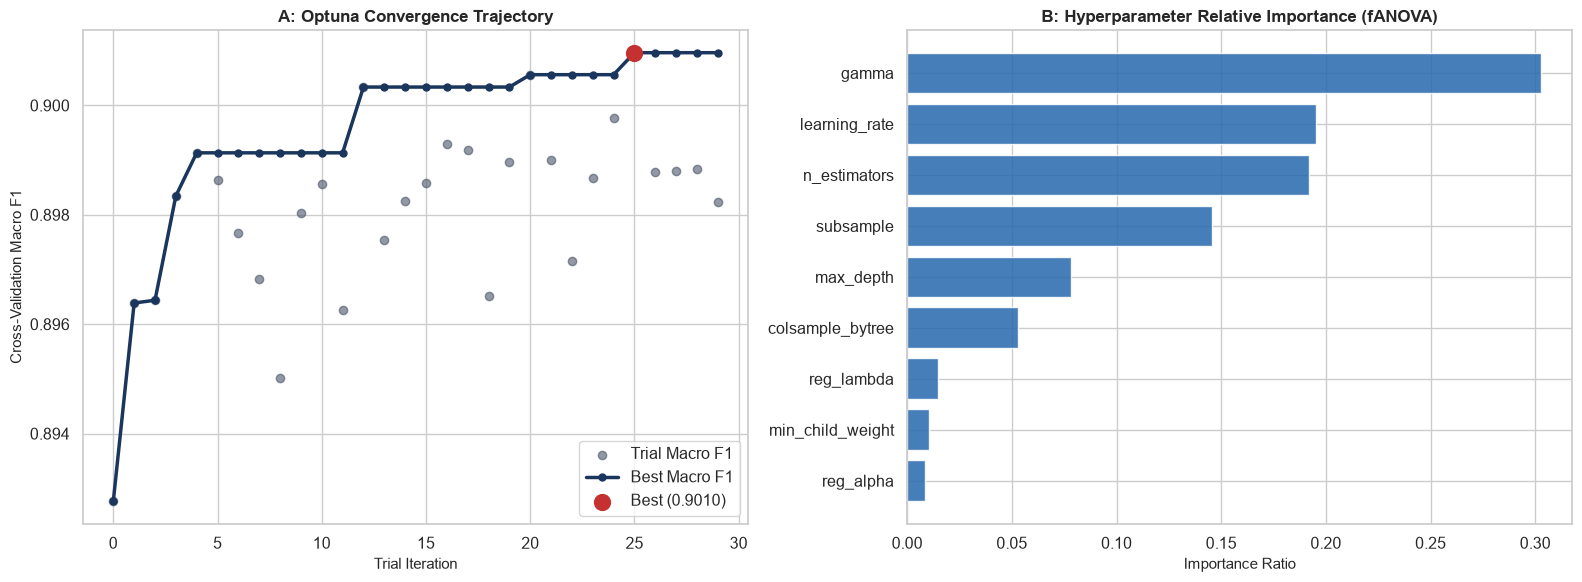

In [4]:
trials_df = study.trials_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

trial_nums = trials_df['number']
trial_values = trials_df['value']
best_values = trial_values.cummax()

axes[0].scatter(trial_nums, trial_values, color='#4A5568', alpha=0.6, label='Trial Macro F1')
axes[0].plot(trial_nums, best_values, color='#1A365D', linewidth=2.5, marker='o', markersize=5, label='Best Macro F1')
axes[0].scatter([study.best_trial.number], [study.best_value], color='#C53030', s=130, zorder=5, label=f'Best ({study.best_value:.4f})')
axes[0].set_title("A: Optuna Convergence Trajectory", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Trial Iteration", fontsize=11)
axes[0].set_ylabel("Cross-Validation Macro F1", fontsize=11)
axes[0].legend(loc='lower right', frameon=True)

param_importances = optuna.importance.get_param_importances(study)
p_names = list(param_importances.keys())[::-1]
p_vals = [param_importances[k] for k in p_names]

axes[1].barh(p_names, p_vals, color='#2B6CB0', alpha=0.88)
axes[1].set_title("B: Hyperparameter Relative Importance (fANOVA)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Importance Ratio", fontsize=11)

plt.tight_layout()
plt.show()

In [5]:
xgb_default = XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=-1)
xgb_default.fit(X_train_trans, y_train)
y_pred_def = xgb_default.predict(X_test_trans)
y_prob_def = xgb_default.predict_proba(X_test_trans)[:, 1]

best_params = study.best_params.copy()
best_params.update({'eval_metric': 'logloss', 'random_state': 42, 'n_jobs': -1})
xgb_champion = XGBClassifier(**best_params)
xgb_champion.fit(X_train_trans, y_train)
y_pred_champ = xgb_champion.predict(X_test_trans)
y_prob_champ = xgb_champion.predict_proba(X_test_trans)[:, 1]

comp_metrics = [
    {
        'Model': 'Baseline Default XGBoost',
        'Accuracy': round(accuracy_score(y_test, y_pred_def), 4),
        'Precision': round(precision_score(y_test, y_pred_def), 4),
        'Recall': round(recall_score(y_test, y_pred_def), 4),
        'Macro_F1': round(f1_score(y_test, y_pred_def, average='macro'), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob_def), 4),
        'Cohen_Kappa': round(cohen_kappa_score(y_test, y_pred_def), 4)
    },
    {
        'Model': 'Bayesian Champion XGBoost',
        'Accuracy': round(accuracy_score(y_test, y_pred_champ), 4),
        'Precision': round(precision_score(y_test, y_pred_champ), 4),
        'Recall': round(recall_score(y_test, y_pred_champ), 4),
        'Macro_F1': round(f1_score(y_test, y_pred_champ, average='macro'), 4),
        'ROC_AUC': round(roc_auc_score(y_test, y_prob_champ), 4),
        'Cohen_Kappa': round(cohen_kappa_score(y_test, y_pred_champ), 4)
    }
]

df_comp = pd.DataFrame(comp_metrics)
display(df_comp)

,Model,Accuracy,Precision,Recall,Macro_F1,ROC_AUC,Cohen_Kappa
0,Baseline Default XGBoost,0.9342,0.9589,0.9612,0.8870,0.9736,0.7740
1,Bayesian Champion XGBoost,0.9440,0.9700,0.9617,0.9057,0.9771,0.8114


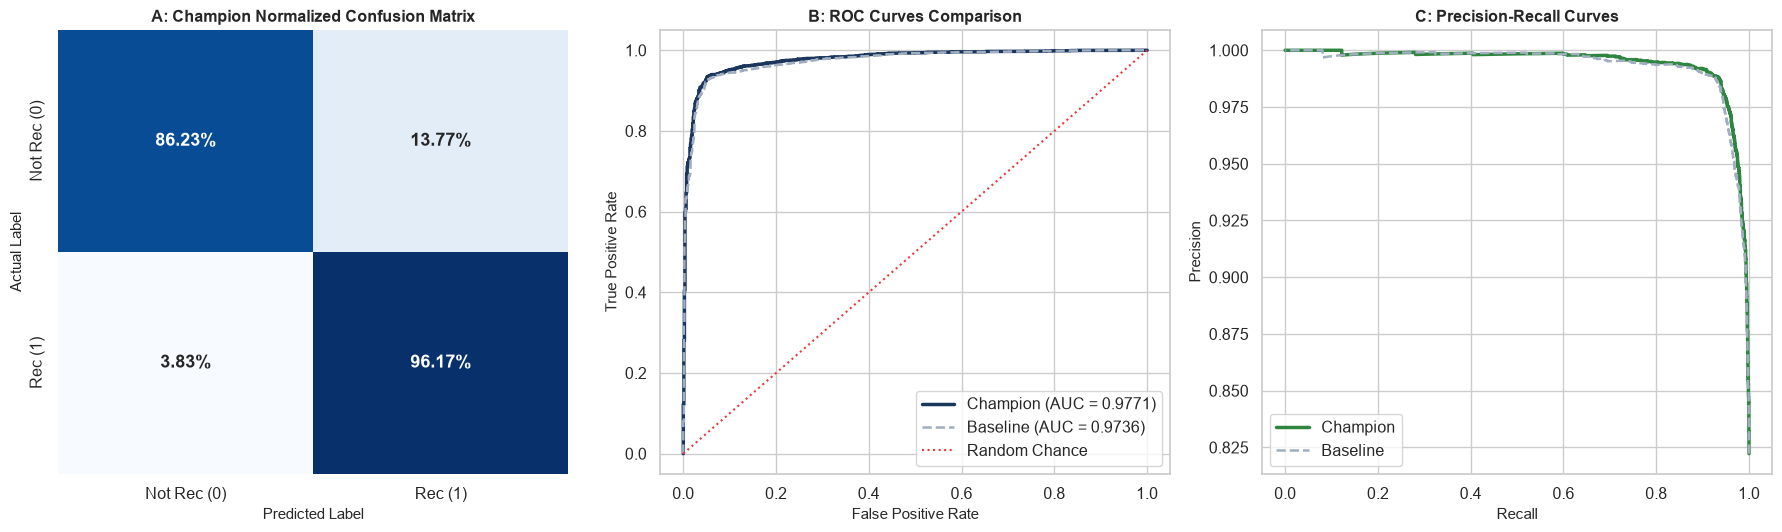

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

cm_champ = confusion_matrix(y_test, y_pred_champ, normalize='true')
sns.heatmap(cm_champ, annot=True, fmt='.2%', cmap='Blues', ax=axes[0], cbar=False, annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title("A: Champion Normalized Confusion Matrix", fontsize=11.5, fontweight='bold')
axes[0].set_xlabel("Predicted Label", fontsize=10.5)
axes[0].set_ylabel("Actual Label", fontsize=10.5)
axes[0].set_xticklabels(['Not Rec (0)', 'Rec (1)'])
axes[0].set_yticklabels(['Not Rec (0)', 'Rec (1)'])

fpr_def, tpr_def, _ = roc_curve(y_test, y_prob_def)
fpr_champ, tpr_champ, _ = roc_curve(y_test, y_prob_champ)
axes[1].plot(fpr_champ, tpr_champ, color='#1A365D', linewidth=2.5, label=f'Champion (AUC = {comp_metrics[1]["ROC_AUC"]:.4f})')
axes[1].plot(fpr_def, tpr_def, color='#A0AEC0', linewidth=1.8, linestyle='--', label=f'Baseline (AUC = {comp_metrics[0]["ROC_AUC"]:.4f})')
axes[1].plot([0, 1], [0, 1], color='#E53E3E', linestyle=':', label='Random Chance')
axes[1].set_title("B: ROC Curves Comparison", fontsize=11.5, fontweight='bold')
axes[1].set_xlabel("False Positive Rate", fontsize=10.5)
axes[1].set_ylabel("True Positive Rate", fontsize=10.5)
axes[1].legend(loc='lower right', frameon=True)

prec_def, rec_def, _ = precision_recall_curve(y_test, y_prob_def)
prec_champ, rec_champ, _ = precision_recall_curve(y_test, y_prob_champ)
axes[2].plot(rec_champ, prec_champ, color='#2E8540', linewidth=2.5, label='Champion')
axes[2].plot(rec_def, prec_def, color='#A0AEC0', linewidth=1.8, linestyle='--', label='Baseline')
axes[2].set_title("C: Precision-Recall Curves", fontsize=11.5, fontweight='bold')
axes[2].set_xlabel("Recall", fontsize=10.5)
axes[2].set_ylabel("Precision", fontsize=10.5)
axes[2].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()

In [7]:
np.random.seed(42)
sample_idx = np.random.choice(len(X_test_trans), size=600, replace=False)
X_test_samp = X_test_trans[sample_idx]
df_samp = df_X_test.iloc[sample_idx].reset_index(drop=True)

explainer = shap.TreeExplainer(xgb_champion)
shap_vals = explainer.shap_values(X_test_samp)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]
elif len(shap_vals.shape) == 3:
    shap_vals = shap_vals[:, :, 1]

shap_interactions = explainer.shap_interaction_values(X_test_samp)
if isinstance(shap_interactions, list):
    shap_interactions = shap_interactions[1]
elif len(shap_interactions.shape) == 4:
    shap_interactions = shap_interactions[:, :, :, 1]

mean_abs_interaction = np.abs(shap_interactions).mean(axis=0)

interaction_pairs = []
n_feats = len(all_feature_names)
for i in range(n_feats):
    for j in range(i + 1, n_feats):
        interaction_pairs.append({
            'Feature_1': all_feature_names[i],
            'Feature_2': all_feature_names[j],
            'Mean_Absolute_Interaction': mean_abs_interaction[i, j]
        })

df_inter = pd.DataFrame(interaction_pairs).sort_values(by='Mean_Absolute_Interaction', ascending=False).reset_index(drop=True)
display(df_inter.head(10))

,Feature_1,Feature_2,Mean_Absolute_Interaction
0,Rating,Sentiment_Neg,0.052617
1,Age,Rating,0.048456
2,Rating,Rating_x_Sentiment,0.044284
3,Rating,Sentiment_Pos,0.040663
4,Rating,Review_Word_Count,0.015402
5,Age,Rating_x_Sentiment,0.014266
6,Rating,Negative_Word_Count,0.013705
7,Rating,Department Name_Tops,0.012899
8,Rating,Review_Length,0.011382
9,Rating,Sentiment_Compound,0.010109


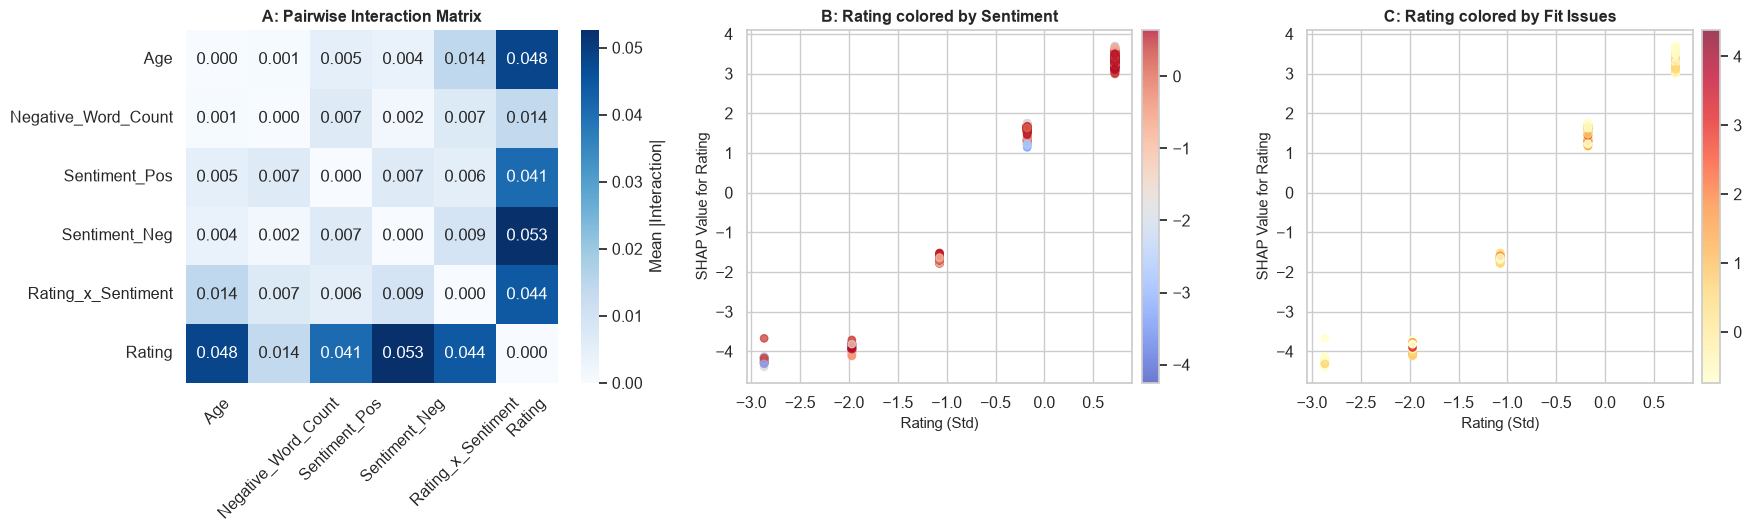

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

top6_idx = np.argsort(np.abs(shap_vals).mean(axis=0))[-6:]
top6_names = [all_feature_names[i] for i in top6_idx]
sub_matrix = mean_abs_interaction[np.ix_(top6_idx, top6_idx)].copy().copy()
np.fill_diagonal(sub_matrix, 0)

sns.heatmap(sub_matrix, xticklabels=top6_names, yticklabels=top6_names, annot=True, fmt='.3f', cmap='Blues', ax=axes[0], cbar_kws={'label': 'Mean |Interaction|'})
axes[0].set_title("A: Pairwise Interaction Matrix", fontsize=11.5, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

idx_rating = all_feature_names.index('Rating')
sc2 = axes[1].scatter(
    df_samp['Rating'], shap_vals[:, idx_rating],
    c=df_samp['Sentiment_Compound'], cmap='coolwarm', alpha=0.75, s=28
)
axes[1].set_title("B: Rating colored by Sentiment", fontsize=11.5, fontweight='bold')
axes[1].set_xlabel("Rating (Std)", fontsize=10.5)
axes[1].set_ylabel("SHAP Value for Rating", fontsize=10.5)
plt.colorbar(sc2, ax=axes[1], pad=0.02)

idx_fit = all_feature_names.index('Fit_Issue_Word_Count')
sc3 = axes[2].scatter(
    df_samp['Rating'], shap_vals[:, idx_rating],
    c=df_samp['Fit_Issue_Word_Count'], cmap='YlOrRd', alpha=0.75, s=28
)
axes[2].set_title("C: Rating colored by Fit Issues", fontsize=11.5, fontweight='bold')
axes[2].set_xlabel("Rating (Std)", fontsize=10.5)
axes[2].set_ylabel("SHAP Value for Rating", fontsize=10.5)
plt.colorbar(sc3, ax=axes[2], pad=0.02)

plt.tight_layout()
plt.show()